# ETL Data Quality Detection

Исследование методов машинного обучения для обнаружения нарушений качества данных в аналитических витринах.

В эксперименте используется датасет Online Retail II. На основе транзакционных данных формируется ежедневная аналитическая витрина с шестью агрегированными показателями.

Для моделирования нарушений качества данных используются три сценария:
- Частичная потеря транзакционных записей.
- Дублирование транзакционных записей.
- Ошибка расчёта суммы продаж.

На основе текущих и исторических показателей формируется 20 признаков для бинарной классификации.

Сравниваются пять методов: Logistic Regression, k-NN, SVM, Random Forest и Gradient Boosting.

Метка 0 обозначает исходное состояние витрины, метка 1 обозначает состояние с искусственно внесённым нарушением.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

rng = np.random.default_rng(42)

path = Path('online_retail_II.csv')
if not path.exists():
    path = Path('online_retail_II.csv.gz')
if not path.exists():
    raise FileNotFoundError('Нужен online_retail_II.csv (или online_retail_II.csv.gz) рядом с ноутбуком')

df = pd.read_csv(
    path, parse_dates=['InvoiceDate'], low_memory=False,
    dtype={'Invoice': 'string', 'StockCode': 'string', 'Description': 'string',
           'Customer ID': 'string', 'Country': 'string'}
)
df['date'] = df['InvoiceDate'].dt.floor('D')
df['line_amount'] = df['Quantity'] * df['Price']
df['is_cancel'] = df['Invoice'].str.startswith('C', na=False)
print('Строк:', len(df))
display(df.head())

Строк: 1067371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,date,line_amount,is_cancel
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12-01,83.4,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,81.0,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,81.0,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12-01,100.8,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12-01,30.0,False


## 1. Первичный анализ данных

Пропуски по столбцам:


,Пропусков
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


Полные дубликаты: 34335
Диапазон дат: 2009-12-01 - 2011-12-09


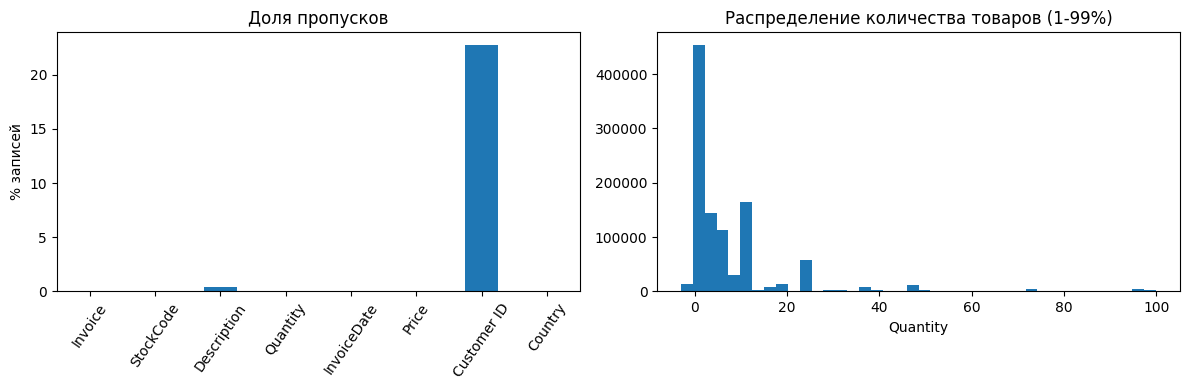

In [2]:
columns = ['Invoice', 'StockCode', 'Description', 'Quantity',
           'InvoiceDate', 'Price', 'Customer ID', 'Country']
print('Пропуски по столбцам:')
display(df[columns].isna().sum().to_frame('Пропусков'))
print('Полные дубликаты:', df[columns].duplicated().sum())
print('Диапазон дат:', df['date'].min().date(), '-', df['date'].max().date())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df[columns].isna().mean() * 100).plot.bar(ax=axes[0])
axes[0].set(title='Доля пропусков', ylabel='% записей')
axes[0].tick_params(axis='x', rotation=55)
q1, q99 = df['Quantity'].quantile([0.01, 0.99])
axes[1].hist(df.loc[df['Quantity'].between(q1, q99), 'Quantity'], bins=40)
axes[1].set(title='Распределение количества товаров (1-99%)', xlabel='Quantity')
plt.tight_layout()
plt.show()

## 2. Дневная аналитическая витрина

Для каждого дня считаем 6 показателей

,n_rows,n_invoices,total_quantity,total_sales,n_products,n_cancel_rows
date,,,,,,
2009-12-01,3223,166,24022,53173.03,1345,110
2009-12-02,3277,133,29942,62763.59,1397,20
2009-12-03,3002,150,44896,68093.05,1335,44
2009-12-04,2559,107,21001,40346.40,1256,27
2009-12-05,402,32,5033,9803.05,287,0


количество записей: 604


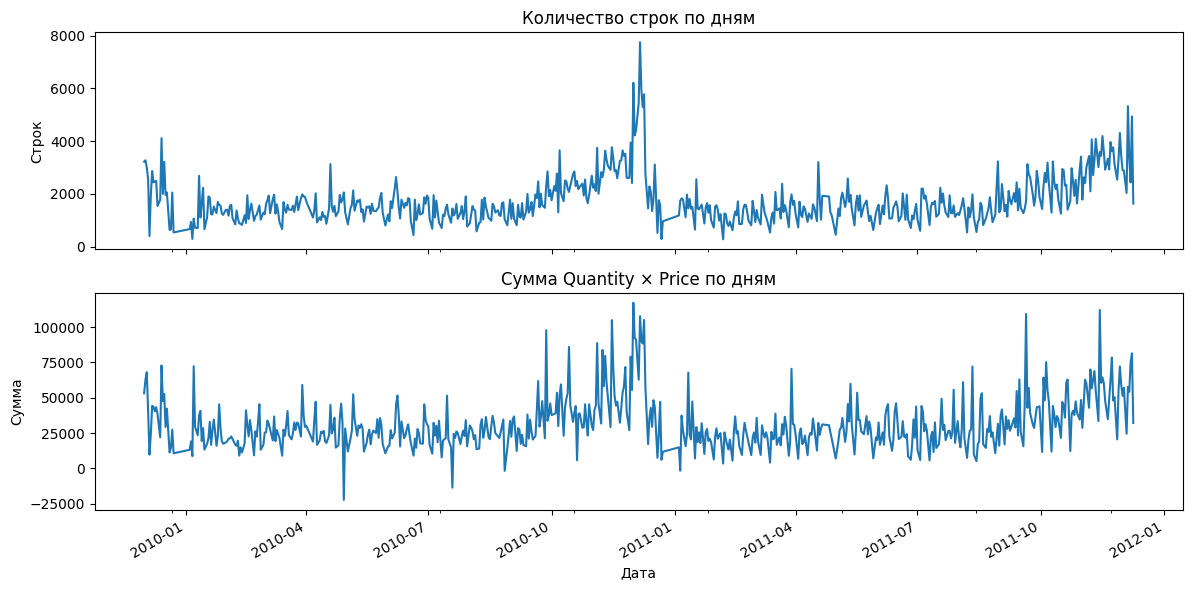

In [3]:
daily = df.groupby('date', sort=True).agg(
    n_rows=('Invoice', 'size'),
    n_invoices=('Invoice', 'nunique'),
    total_quantity=('Quantity', 'sum'),
    total_sales=('line_amount', 'sum'),
    n_products=('StockCode', 'nunique'),
    n_cancel_rows=('is_cancel', 'sum')
)
display(daily.head())
print('количество записей:', len(daily))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
daily['n_rows'].plot(ax=axes[0])
axes[0].set(title='Количество строк по дням', ylabel='Строк')
daily['total_sales'].plot(ax=axes[1])
axes[1].set(title='Сумма Quantity × Price по дням', ylabel='Сумма', xlabel='Дата')
plt.tight_layout()
plt.show()

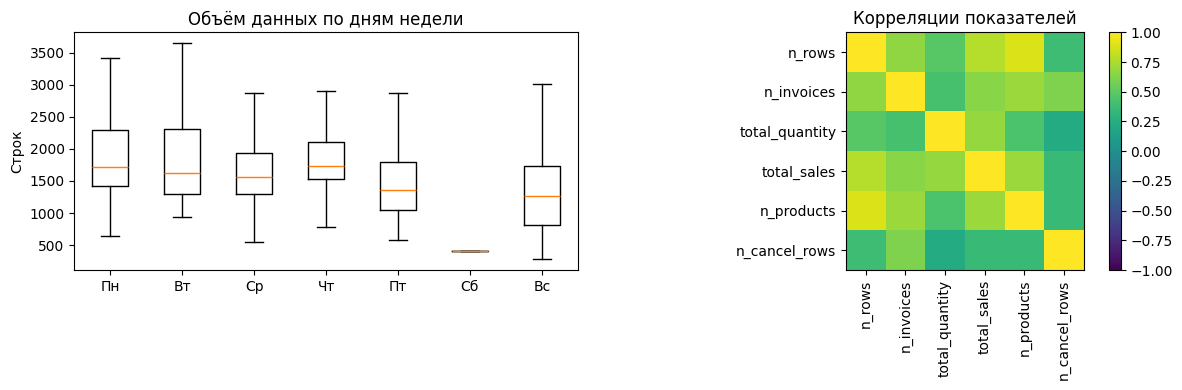

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_weekday = [daily.loc[daily.index.dayofweek == i, 'n_rows'].values for i in range(7)]
axes[0].boxplot(by_weekday, tick_labels=['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'], showfliers=False)
axes[0].set(title='Объём данных по дням недели', ylabel='Строк')
correlations = daily.corr(numeric_only=True)
img = axes[1].imshow(correlations, vmin=-1, vmax=1)
axes[1].set_xticks(range(6), correlations.columns, rotation=90)
axes[1].set_yticks(range(6), correlations.index)
axes[1].set_title('Корреляции показателей')
fig.colorbar(img, ax=axes[1], fraction=0.045)
plt.tight_layout()
plt.show()

## 3. Подготовка набора для классификации

Создаём по две версии каждого дня: без изменений ('0') и с одной ошибкой ('1'). Моделируем потерю строк, дублирование строк или ошибку расчёта суммы. Крайние даты исключаем как потенциально неполные.

In [5]:
data_days = daily.iloc[1:-1].copy()  # 602 дня
n_days = len(data_days)
train_end = int(n_days * 0.60)
val_end = int(n_days * 0.80)

splits = {}
for name, dates in [
    ('train', data_days.index[:train_end]),
    ('validation', data_days.index[train_end:val_end]),
    ('test', data_days.index[val_end:])
]:
    for date in dates:
        splits[date] = name

print('Дней:', n_days, '| Train:', train_end,
      '| Validation:', val_end-train_end, '| Test:', n_days-val_end)

Дней: 602 | Train: 361 | Validation: 120 | Test: 121


In [6]:
# формируем одну повреждённую версию для каждой исходной даты
rows = []
for date, transactions in df.groupby('date', sort=True):
    if date not in splits:
        continue

    original = data_days.loc[date].to_dict()
    changed = original.copy()
    scenario = rng.choice(['loss', 'duplicate', 'sales_error'])
    part = rng.uniform(0.15, 0.55)
    count = max(1, min(len(transactions)-1, round(len(transactions) * part)))
    chosen = rng.choice(len(transactions), size=count, replace=False)
    selected = transactions.iloc[chosen]

    if scenario == 'loss':
        remaining = transactions.drop(transactions.index[chosen])
        changed = {
            'n_rows': len(remaining),
            'n_invoices': remaining['Invoice'].nunique(),
            'total_quantity': remaining['Quantity'].sum(),
            'total_sales': remaining['line_amount'].sum(),
            'n_products': remaining['StockCode'].nunique(),
            'n_cancel_rows': remaining['is_cancel'].sum()
        }
    elif scenario == 'duplicate':
        changed['n_rows'] += len(selected)
        changed['total_quantity'] += selected['Quantity'].sum()
        changed['total_sales'] += selected['line_amount'].sum()
        changed['n_cancel_rows'] += selected['is_cancel'].sum()
    else:
        changed['total_sales'] -= selected['line_amount'].sum()

    rows.append({'date': date, **original, 'label': 0, 'split': splits[date]})
    rows.append({'date': date, **changed, 'label': 1, 'split': splits[date]})

samples = pd.DataFrame(rows).sort_values(['date', 'label']).reset_index(drop=True)
metrics = list(daily.columns)
print('Объектов классификации:', len(samples))
print('Классы:', samples['label'].value_counts().to_dict())
reference = samples[samples.label == 0].set_index('date')[metrics]
modified = samples[samples.label == 1].set_index('date')[metrics]
assert ((modified - reference).abs().sum(axis=1) > 0).all()

Объектов классификации: 1204
Классы: {0: 602, 1: 602}


### Признаки

Для каждого из 6 показателей берём текущее значение и отклонения от истории: предыдущих 7 наблюдений и 4 предыдущих наблюдений того же дня недели. Добавляем день недели и месяц - всего 20 признаков.

In [7]:
history = data_days.copy()
for col in metrics:
    history[f'prev7_{col}'] = history[col].shift(1).rolling(7, min_periods=3).median()
    history[f'weekday4_{col}'] = history.groupby(history.index.dayofweek)[col].transform(
        lambda s: s.shift(1).rolling(4, min_periods=2).median()
    )

samples = samples.join(history.drop(columns=metrics), on='date')
samples['weekday'] = samples['date'].dt.dayofweek
samples['month'] = samples['date'].dt.month
for col in metrics:
    for prefix in ['prev7', 'weekday4']:
        base = samples[f'{prefix}_{col}']
        samples[f'dev_{prefix}_{col}'] = (samples[col] - base) / base.abs().clip(lower=1)

features = (metrics + ['weekday', 'month'] +
            [c for c in samples if c.startswith('dev_')])
train = samples[samples.split == 'train']
validation = samples[samples.split == 'validation']
test = samples[samples.split == 'test']
print('Признаков:', len(features))
print('Train:', len(train), '| Validation:', len(validation), '| Test:', len(test))
assert len(features) == 20
assert set(train.date).isdisjoint(test.date)

Признаков: 20
Train: 722 | Validation: 240 | Test: 242


## 4. Пять классификаторов и разделяющие границы

Каждый классификатор обучаем на 20 признаках. Чтобы нарисовать двумерную разделяющую границу, отдельно обучаем его копию на двух признаках: отклонении количества строк и суммы от последних 7 наблюдений

In [8]:
boundary_features = ['dev_prev7_n_rows', 'dev_prev7_total_sales']
models = {}

def plot_boundary(name, trained_model):
    model_2d = clone(trained_model)
    model_2d.fit(train[boundary_features], train['label'])

    xy = train[boundary_features].to_numpy(dtype=float)

    a, b = np.nanquantile(xy[:, 0], [0.02, 0.98])
    c, d = np.nanquantile(xy[:, 1], [0.02, 0.98])

    xpad = max((b-a)*0.1, 0.03)
    ypad = max((d-c)*0.1, 0.03)

    xx, yy = np.meshgrid(np.linspace(a-xpad, b+xpad, 100),
                         np.linspace(c-ypad, d+ypad, 100))
    grid = pd.DataFrame({boundary_features[0]: xx.ravel(),
                         boundary_features[1]: yy.ravel()})
    prediction = model_2d.predict(grid).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.contourf(xx, yy, prediction, levels=[-0.5, 0.5, 1.5], alpha=0.3)
    ax.scatter(xy[:, 0], xy[:, 1], c=train['label'], s=9, alpha=0.5)
    
    ax.set(xlabel='Отклонение количества строк', ylabel='Отклонение суммы продаж',
           title=f'{name}: разделяющая граница (2 признака)',
           xlim=(a-xpad, b+xpad), ylim=(c-ypad, d+ypad))
    
    plt.tight_layout()
    plt.show()

def fit_and_plot(name, model):
    model.fit(train[features], train['label'])
    models[name] = model
    pred = model.predict(validation[features])
    print(f'F1 на Validation: {f1_score(validation.label, pred):.3f}')
    plot_boundary(name, model)

### 4.1. Logistic Regression

F1 на Validation: 0.690


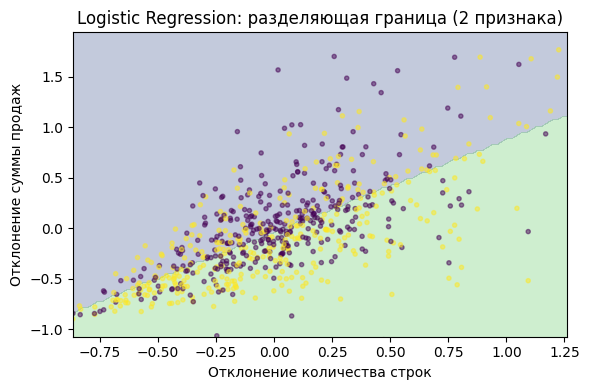

In [9]:
lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                   LogisticRegression(max_iter=1200, class_weight='balanced', random_state=42))
fit_and_plot('Logistic Regression', lr)

### 4.2. k-Nearest Neighbors

F1 на Validation: 0.650


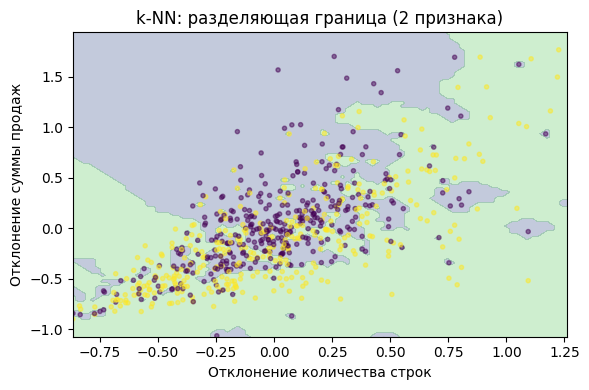

In [10]:
knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                    KNeighborsClassifier(n_neighbors=11, weights='distance'))
fit_and_plot('k-NN', knn)

### 4.3. SVM (RBF)

F1 на Validation: 0.720


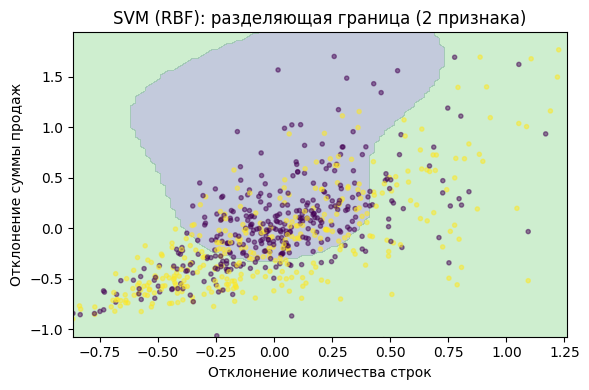

In [11]:
svm = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                    SVC(kernel='rbf', C=1.0, class_weight='balanced', random_state=42))
fit_and_plot('SVM (RBF)', svm)

### 4.4. Random Forest

F1 на Validation: 0.722


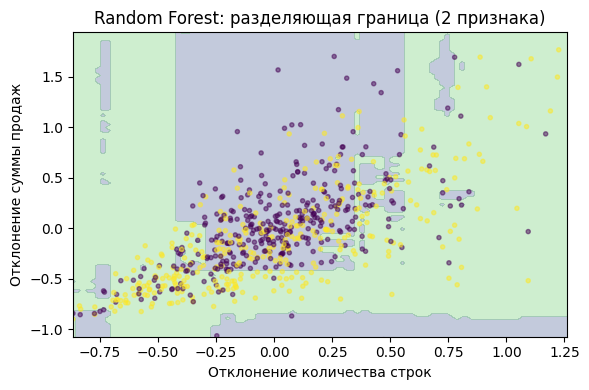

In [12]:
rf = make_pipeline(SimpleImputer(strategy='median'),
                   RandomForestClassifier(n_estimators=200, max_depth=7,
                                          class_weight='balanced', random_state=42, n_jobs=-1))
fit_and_plot('Random Forest', rf)

### 4.5. Gradient Boosting

F1 на Validation: 0.705


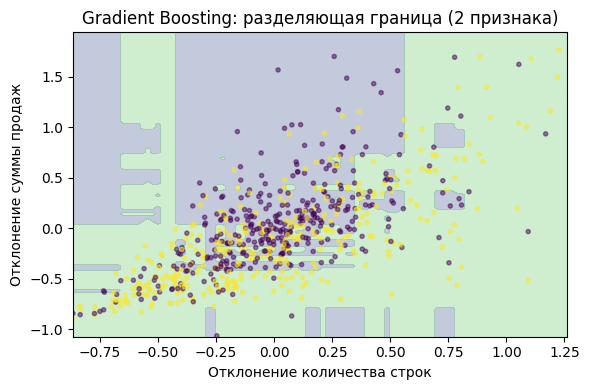

In [13]:
gb = make_pipeline(SimpleImputer(strategy='median'),
                   HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15,
                                                  learning_rate=0.06, l2_regularization=1.0,
                                                  random_state=42))
fit_and_plot('Gradient Boosting', gb)

## 5. Сравнение результатов

Сравниваем пять моделей на одинаковом отложенном Test по Precision, Recall и F1.

,Модель,F1_validation
3,Random Forest,0.722
2,SVM (RBF),0.720
4,Gradient Boosting,0.705
0,Logistic Regression,0.690
1,k-NN,0.650


Модель выбрана по Validation: Random Forest


,Модель,Precision,Recall,F1,FPR,FP,FN
0,Logistic Regression,0.745,0.678,0.710,0.231,28,39
1,k-NN,0.678,0.488,0.567,0.231,28,62
2,SVM (RBF),0.786,0.760,0.773,0.207,25,29
3,Random Forest,0.780,0.702,0.739,0.198,24,36
4,Gradient Boosting,0.746,0.727,0.736,0.248,30,33


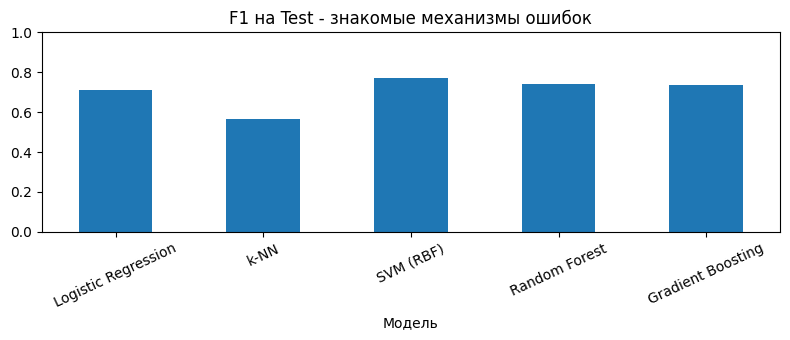

In [14]:
validation_results = []

for name, model in models.items():
    pred = model.predict(validation[features])
    validation_results.append({'Модель': name, 'F1_validation': f1_score(validation.label, pred)})

validation_table = pd.DataFrame(validation_results).sort_values('F1_validation', ascending=False)
best_name = validation_table.iloc[0]['Модель']
display(validation_table.round(3))
print('Модель выбрана по Validation:', best_name)

results = []

for name, model in models.items():
    pred = model.predict(test[features])
    tn, fp, fn, tp = confusion_matrix(test.label, pred, labels=[0, 1]).ravel()
    results.append({'Модель': name, 'Precision': precision_score(test.label, pred, zero_division=0),
                    'Recall': recall_score(test.label, pred), 'F1': f1_score(test.label, pred),
                    'FPR': fp / (fp + tn), 'FP': fp, 'FN': fn})
    
result_table = pd.DataFrame(results)
display(result_table.round(3))
result_table.plot.bar(x='Модель', y='F1', legend=False, ylim=(0, 1), figsize=(8, 3.5), rot=25)

plt.title('F1 на Test - знакомые механизмы ошибок')
plt.tight_layout()
plt.show()

result_table.to_csv('etl_data_quality_results.csv', index=False)

На Test сравниваются все пять фиксированных моделей. Выбор основной модели выполняется по F1 на Validation; результаты Test не используются для изменения параметров.

## 6. Проверка на новых механизмах ошибок

В обучении использовались потеря случайных строк, дублирование и исключение части суммы операций. Теперь проверим те же обученные модели на трёх других механизмах:

1) Потеря заказов: удаляем все строки выбранных Invoice и заново считаем показатели. Так можно приблизить пропуск целых групп записей при загрузке.
2) Устаревшая витрина: вместо текущих показателей публикуем показатели предыдущего дня с операциями. Это пример сбоя обновления.
3) Ошибка масштаба цены: умножаем Price выбранных заказов на 100 и пересчитываем суммы. Это пример ошибки единиц измерения цены.

Эти генераторы реализованы отдельно от обучающего. Все три механизма отсутствуют в Train и Validation

Для каждого сценария создаём исходную и повреждённую версии тех же дней. Проверяем пары, разделение дат и фактическое изменение показателей

In [15]:
# все версии одного дня должны находиться в одной выборке
assert set(train.date).isdisjoint(validation.date)
assert set(train.date).isdisjoint(test.date)
assert set(validation.date).isdisjoint(test.date)

assert train.date.max() < validation.date.min()
assert validation.date.max() < test.date.min()
assert samples.groupby('date')['split'].nunique().eq(1).all()

assert samples.groupby('date').label.apply(lambda x: sorted(x) == [0, 1]).all()
assert ((modified - reference).abs().sum(axis=1) > 0).all()
assert not set(features) & {'label', 'split', 'scenario', 'date'}

print('Проверки дат, исходных пар и признаков пройдены.')

Проверки дат, исходных пар и признаков пройдены.


In [16]:
def aggregate_day(t):
    return {'n_rows': len(t), 'n_invoices': t.Invoice.nunique(),
            'total_quantity': t.Quantity.sum(), 'total_sales': t.line_amount.sum(),
            'n_products': t.StockCode.nunique(), 'n_cancel_rows': t.is_cancel.sum()}

scenarios = ['Потеря заказов', 'Устаревшая витрина', 'Ошибка масштаба цены']
test_transactions = df.loc[df.date.isin(test.date)]

new_rows = []

for scenario in scenarios:
    random = np.random.default_rng(101)

    for date, transactions in test_transactions.groupby('date', sort=True):
        original = daily.loc[date, metrics].to_dict()

        if scenario == 'Устаревшая витрина':
            previous_date = daily.index[daily.index < date][-1]
            changed = daily.loc[previous_date, metrics].to_dict()
        else:
            invoices = transactions.Invoice.dropna().unique()
            count = max(1, round(len(invoices) * random.uniform(0.15, 0.55)))
            selected = random.choice(invoices, count, replace=False)

            if scenario == 'Потеря заказов':
                damaged = transactions.loc[~transactions.Invoice.isin(selected)]
            else:
                damaged = transactions.copy()
                damaged.loc[damaged.Invoice.isin(selected), 'Price'] *= 100
                damaged['line_amount'] = damaged.Quantity * damaged.Price
            changed = aggregate_day(damaged)
        assert sum(abs(changed[c] - original[c]) for c in metrics) > 1e-8
        
        for label, values in [(0, original), (1, changed)]:
            new_rows.append({'date': date, 'scenario': scenario, 'label': label, **values})

new_test = pd.DataFrame(new_rows)
# та же история и те же 20 признаков, что в основном эксперименте
new_test = new_test.join(history.drop(columns=metrics), on='date')
new_test['weekday'] = new_test.date.dt.dayofweek
new_test['month'] = new_test.date.dt.month

for col in metrics:
    
    for prefix in ['prev7', 'weekday4']:
        base = new_test[f'{prefix}_{col}']
        new_test[f'dev_{prefix}_{col}'] = (new_test[col] - base) / base.abs().clip(lower=1)

assert set(new_test.date) == set(test.date)
assert new_test.groupby(['scenario', 'date']).label.apply(lambda x: sorted(x) == [0, 1]).all()

# исходные состояния и их признаки должны совпадать с исходным Test
for scenario in scenarios:
    clean = new_test.loc[(new_test.scenario == scenario) & (new_test.label == 0)]
    clean = clean.set_index('date')[features].sort_index()
    expected = test.loc[test.label == 0].set_index('date')[features].sort_index()
    pd.testing.assert_frame_equal(clean, expected, check_dtype=False)

print('Подготовлено пар в каждом сценарии:', new_test.date.nunique())
print('Новые повреждения, пары и исходные признаки проверены.')

Подготовлено пар в каждом сценарии: 121
Новые повреждения, пары и исходные признаки проверены.


In [17]:
transfer_results = []

for scenario in scenarios:
    check = new_test.loc[new_test.scenario == scenario]
    for name, model in models.items():
        prediction = model.predict(check[features])
        tn, fp, fn, tp = confusion_matrix(check.label, prediction, labels=[0, 1]).ravel()
        transfer_results.append({'Сценарий': scenario, 'Модель': name,
            'Precision': precision_score(check.label, prediction, zero_division=0),
            'Recall': recall_score(check.label, prediction),
            'F1': f1_score(check.label, prediction), 'FPR': fp / (fp + tn)})
transfer_table = pd.DataFrame(transfer_results)

with pd.option_context('display.max_rows', 20, 'display.max_columns', None):
    display(transfer_table.round(3))
    
print('Основная модель выбрана ранее по Validation:', best_name)

,Сценарий,Модель,Precision,Recall,F1,FPR
0,Потеря заказов,Logistic Regression,0.641,0.413,0.503,0.231
1,Потеря заказов,k-NN,0.654,0.438,0.525,0.231
2,Потеря заказов,SVM (RBF),0.679,0.438,0.533,0.207
3,Потеря заказов,Random Forest,0.718,0.504,0.592,0.198
4,Потеря заказов,Gradient Boosting,0.531,0.281,0.368,0.248
5,Устаревшая витрина,Logistic Regression,0.517,0.248,0.335,0.231
6,Устаревшая витрина,k-NN,0.404,0.157,0.226,0.231
7,Устаревшая витрина,SVM (RBF),0.510,0.215,0.302,0.207
8,Устаревшая витрина,Random Forest,0.415,0.140,0.210,0.198
9,Устаревшая витрина,Gradient Boosting,0.375,0.149,0.213,0.248


Основная модель выбрана ранее по Validation: Random Forest


## Вывод

На знакомых типах ошибок F1 модели Random Forest составил 0,739. На новых типах ошибок результат снизился: потеря заказов 0,592, устаревшая витрина 0,210, ошибка масштаба цены 0,105. Модель хуже обнаруживает ошибки, которых не было при обучении.